### networkx 4: Euler-Wege, Färbungen, Dominating Sets und Rundreisen - Übungen

In diesem Notebook geht es um bekannte **Probleme** auf Graphen. Einige sind leicht zu lösen (Euler-Wege), für andere kennt man kein schnelles Verfahren
(Färbungen mit möglichst wenigen Farben, Dominating Sets, Rundreisen). Für diese benutzt man **Näherungsverfahren**, z. B. **Greedy-Verfahren**, die in jedem Schritt
das im Moment Beste wählen, und vergleicht sie bei kleinen Graphen mit dem Ausprobieren aller Möglichkeiten.

Die Reihe hat vier Notebooks:

1. Grundlagen: Graphen erstellen, untersuchen und zeichnen
2. Suchen: Wege, Zusammenhang, Breiten- und Tiefensuche, Abhängigkeiten
3. Gewichtete Graphen: kürzeste Wege (Dijkstra, Bellman-Ford), minimale Spannbäume
4. **Probleme**: Euler-Wege, Färbungen, Dominating Sets, Rundreisen, soziale Netze (dieses Notebook)

Die Inhalte gehen über das Basisfach hinaus und sind vor allem für das **Leistungsfach** gedacht. Zum Ausprobieren aller Möglichkeiten brauchst du `combinations` und `permutations`
aus dem Notebook zu `itertools`.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Euler-Wege

#### Jede Kante genau einmal

Ein **Euler-Weg** benutzt **jede Kante genau einmal** („Haus vom Nikolaus“: in einem Zug zeichnen, ohne abzusetzen). Endet er dort, wo er begonnen hat, heißt er **Euler-Kreis**.

Für zusammenhängende Graphen gilt (Euler, 1736):
- Es gibt einen Euler-Kreis genau dann, wenn **alle** Knoten geraden Grad haben.
- Es gibt einen Euler-Weg (aber keinen Kreis) genau dann, wenn **genau zwei** Knoten ungeraden Grad haben. Er beginnt an einem und endet am anderen.

| Aufruf | Ergebnis |
|---|---|
| `nx.is_eulerian(G)` | gibt es einen Euler-Kreis? |
| `nx.has_eulerian_path(G)` | gibt es einen Euler-Weg? |
| `list(nx.eulerian_circuit(G))` | ein Euler-Kreis als Liste von Kanten |
| `list(nx.eulerian_path(G, source=v))` | ein Euler-Weg ab v als Liste von Kanten |

In [ ]:
import networkx as nx

haus = nx.Graph([(1, 2), (2, 3), (3, 4), (4, 1), (1, 3), (2, 4), (3, 5), (4, 5)])
print(dict(haus.degree))
print(nx.is_eulerian(haus), nx.has_eulerian_path(haus))
print(list(nx.eulerian_path(haus, source=1)))

#### Mehrfachkanten: `MultiGraph`

Ein gewöhnlicher `Graph` hat zwischen zwei Knoten höchstens eine Kante. Ein `nx.MultiGraph()` erlaubt **mehrere** Kanten zwischen denselben Knoten, z. B. zwei Brücken zwischen
denselben Ufern. Sonst funktioniert er wie ein `Graph`.

In [ ]:
import networkx as nx

M = nx.MultiGraph()
M.add_edge('Ufer', 'Insel')
M.add_edge('Ufer', 'Insel')
print(M.number_of_edges(), M.degree('Ufer'))

#### Aufgabe 1.1

Die **Königsberger Brücken**: Die Stadtteile N (Nordufer), S (Südufer), I (Insel) und O (Ostteil) sind durch sieben Brücken verbunden: zwei zwischen N und I, zwei zwischen S und I,
je eine zwischen N und O, S und O, I und O. Baue den `MultiGraph`, gib die Grade aus und ob es einen Euler-Weg gibt.

**Erwartete Ausgabe:**
```
{'N': 3, 'I': 5, 'S': 3, 'O': 3}
False
```

In [ ]:
import networkx as nx
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx
K = nx.MultiGraph([('N', 'I'), ('N', 'I'), ('S', 'I'), ('S', 'I'), ('N', 'O'), ('S', 'O'), ('I', 'O')])
print(dict(K.degree))
print(nx.has_eulerian_path(K))
```

</details>

#### Aufgabe 1.2

Welche **eine** zusätzliche Brücke macht in Königsberg einen Euler-Weg möglich? Probiere jede mögliche neue Brücke zwischen zwei verschiedenen Stadtteilen (mit `combinations`) und gib
die Paare aus, bei denen es danach einen Euler-Weg gibt.

**Erwartete Ausgabe:**
```
N S
N I
N O
S I
S O
I O
```

In [ ]:
from itertools import combinations
import networkx as nx

kanten = [('N', 'I'), ('N', 'I'), ('S', 'I'), ('S', 'I'), ('N', 'O'), ('S', 'O'), ('I', 'O')]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from itertools import combinations
import networkx as nx

kanten = [('N', 'I'), ('N', 'I'), ('S', 'I'), ('S', 'I'), ('N', 'O'), ('S', 'O'), ('I', 'O')]
for u, v in combinations(['N', 'S', 'I', 'O'], 2):
    K = nx.MultiGraph(kanten)
    K.add_edge(u, v)
    if nx.has_eulerian_path(K):
        print(u, v)
```

</details>

#### Aufgabe 1.3

Gib für jede Figur in `figuren` aus, ob man sie in einem Zug zeichnen kann (Euler-Weg) und ob man dabei wieder am Start ankommt (Euler-Kreis).

**Erwartete Ausgabe:**
```
Quadrat True True
Quadrat mit Diagonale True False
Quadrat mit Diagonalen False False
Stern False False
```

In [ ]:
import networkx as nx

figuren = {'Quadrat': nx.cycle_graph(4), 'Quadrat mit Diagonale': nx.Graph([(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)]),
           'Quadrat mit Diagonalen': nx.Graph([(0, 1), (1, 2), (2, 3), (3, 0), (0, 2), (1, 3)]), 'Stern': nx.Graph([(0, 1), (0, 2), (0, 3)])}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

figuren = {'Quadrat': nx.cycle_graph(4), 'Quadrat mit Diagonale': nx.Graph([(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)]),
           'Quadrat mit Diagonalen': nx.Graph([(0, 1), (1, 2), (2, 3), (3, 0), (0, 2), (1, 3)]), 'Stern': nx.Graph([(0, 1), (0, 2), (0, 3)])}
for name, G in figuren.items():
    print(name, nx.has_eulerian_path(G), nx.is_eulerian(G))
```

</details>

#### Aufgabe 1.4

Für das Haus vom Nikolaus haben die Knoten 1 und 2 ungeraden Grad. Gib einen Euler-Weg ab 1 und einen ab 2 aus und prüfe für beide, dass sie alle 8 Kanten genau einmal benutzen
(Anzahl der Kanten im Weg).

**Erwartete Ausgabe:**
```
[(1, 2), (2, 3), (3, 1), (1, 4), (4, 3), (3, 5), (5, 4), (4, 2)] 8
[(2, 1), (1, 4), (4, 2), (2, 3), (3, 4), (4, 5), (5, 3), (3, 1)] 8
```

In [ ]:
import networkx as nx

haus = nx.Graph([(1, 2), (2, 3), (3, 4), (4, 1), (1, 3), (2, 4), (3, 5), (4, 5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

haus = nx.Graph([(1, 2), (2, 3), (3, 4), (4, 1), (1, 3), (2, 4), (3, 5), (4, 5)])
for start in [1, 2]:
    weg = list(nx.eulerian_path(haus, source=start))
    print(weg, len(weg))
```

</details>

#### Aufgabe 1.5

Ein Schneepflug soll jede Straße eines Viertels genau einmal räumen und zum Depot `D` zurückkehren. Prüfe, ob das geht, und gib die Route als Liste von Knoten aus (erster Knoten jeder Kante
plus der letzte Endknoten).

**Erwartete Ausgabe:**
```
True
['D', 'b', 'f', 'e', 'b', 'a', 'd', 'c', 'a', 'D']
```

In [ ]:
import networkx as nx

V = nx.Graph([('D', 'a'), ('a', 'b'), ('b', 'D'), ('a', 'c'), ('c', 'd'), ('d', 'a'), ('b', 'e'), ('e', 'f'), ('f', 'b')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

V = nx.Graph([('D', 'a'), ('a', 'b'), ('b', 'D'), ('a', 'c'), ('c', 'd'), ('d', 'a'), ('b', 'e'), ('e', 'f'), ('f', 'b')])
print(nx.is_eulerian(V))
kreis = list(nx.eulerian_circuit(V, source='D'))
route = []
for u, v in kreis:
    route.append(u)
route.append(kreis[-1][1])
print(route)
```

</details>

#### Aufgabe 1.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import networkx as nx

G = nx.path_graph(4)
print(dict(G.degree))
print(nx.has_eulerian_path(G), nx.is_eulerian(G))
print(nx.is_eulerian(nx.cycle_graph(5)))

## 2. Färbungen

#### Benachbarte Knoten verschieden färben

Eine **Färbung** gibt jedem Knoten eine Farbe (eine Zahl 0, 1, 2, …), sodass **benachbarte Knoten verschiedene Farben** haben. Gesucht sind möglichst wenige Farben.
Anwendungen: Landkarten (Nachbarländer verschieden), Klausurtermine (Kurse mit gemeinsamen Schülern nicht gleichzeitig), Frequenzen von Sendern.

Die kleinste mögliche Farbzahl zu finden ist schwer. `nx.greedy_color(G)` färbt **gierig**: Es geht die Knoten nacheinander durch und gibt jedem die kleinste Farbe, die kein schon gefärbter Nachbar hat.
Standardmäßig beginnt es mit den Knoten mit dem **größten Grad**. Das Ergebnis ist ein Dictionary Knoten → Farbe; die Farbzahl ist `max(farben.values()) + 1`.

Für Landkarten gilt der **Vierfarbensatz**: Vier Farben reichen immer.

In [ ]:
import networkx as nx

G = nx.Graph([('a', 'b'), ('b', 'c'), ('c', 'a'), ('c', 'd'), ('d', 'e'), ('e', 'c')])
farben = nx.greedy_color(G)
print(farben)
print(max(farben.values()) + 1)

#### Die Reihenfolge entscheidet

Das Greedy-Verfahren hängt von der **Reihenfolge** ab, in der die Knoten gefärbt werden. Mit `strategy=funktion` gibt man eine eigene Reihenfolge vor: eine Funktion mit den Parametern
`G` und `farben`, die die Knoten in der gewünschten Reihenfolge zurückgibt. Eine schlechte Reihenfolge kann viel mehr Farben brauchen als nötig.

In [ ]:
import networkx as nx

# ein „Kronengraph“: a_i ist mit allen b_j verbunden, außer mit b_i
G = nx.Graph()
for i in range(4):
    for j in range(4):
        if i != j:
            G.add_edge(f'a{i}', f'b{j}')

def abwechselnd(G, farben):
    return ['a0', 'b0', 'a1', 'b1', 'a2', 'b2', 'a3', 'b3']

def erst_a(G, farben):
    return ['a0', 'a1', 'a2', 'a3', 'b0', 'b1', 'b2', 'b3']

print(max(nx.greedy_color(G, strategy=abwechselnd).values()) + 1)
print(max(nx.greedy_color(G, strategy=erst_a).values()) + 1)

#### Aufgabe 2.1

Die Bundesländer (`D`, Nachbarländer sind verbunden): Färbe die Karte mit `greedy_color` und gib die Anzahl der Farben aus. Gib dann für jede Farbe die Länder dieser Farbe sortiert aus.

**Erwartete Ausgabe:**
```
5
0 ['BE', 'BY', 'NI', 'RP']
1 ['BB', 'HB', 'HE', 'SH', 'SL']
2 ['BW', 'HH', 'MV', 'NW', 'TH']
3 ['SN']
4 ['ST']
```

In [ ]:
import networkx as nx

nachbarn = {'BW': ['BY', 'HE', 'RP'], 'BY': ['HE', 'TH', 'SN'], 'BE': ['BB'], 'BB': ['MV', 'SN', 'ST', 'NI'], 'HB': ['NI'], 'HH': ['SH', 'NI'],
            'HE': ['TH', 'NI', 'NW', 'RP'], 'MV': ['SH', 'NI'], 'NI': ['SH', 'ST', 'TH', 'NW'], 'NW': ['RP'], 'RP': ['SL'], 'SN': ['TH', 'ST'], 'ST': ['TH']}
D = nx.Graph(nachbarn)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

nachbarn = {'BW': ['BY', 'HE', 'RP'], 'BY': ['HE', 'TH', 'SN'], 'BE': ['BB'], 'BB': ['MV', 'SN', 'ST', 'NI'], 'HB': ['NI'], 'HH': ['SH', 'NI'],
            'HE': ['TH', 'NI', 'NW', 'RP'], 'MV': ['SH', 'NI'], 'NI': ['SH', 'ST', 'TH', 'NW'], 'NW': ['RP'], 'RP': ['SL'], 'SN': ['TH', 'ST'], 'ST': ['TH']}
D = nx.Graph(nachbarn)
farben = nx.greedy_color(D)
anzahl = max(farben.values()) + 1
print(anzahl)
for f in range(anzahl):
    laender = []
    for land, farbe in farben.items():
        if farbe == f:
            laender.append(land)
    print(f, sorted(laender))
```

</details>

#### Aufgabe 2.2

Nach dem Vierfarbensatz reichen für die Bundesländer 4 Farben, das Greedy-Verfahren mit der Standard-Reihenfolge braucht aber mehr. Färbe mit der Reihenfolge `reihe`
(Niedersachsen zuerst, dann von innen nach außen): Schreibe eine Funktion, die `reihe` zurückgibt, und übergib sie mit `strategy=`. Gib die Anzahl der Farben aus.

**Erwartete Ausgabe:**
```
4
```

In [ ]:
import networkx as nx

nachbarn = {'BW': ['BY', 'HE', 'RP'], 'BY': ['HE', 'TH', 'SN'], 'BE': ['BB'], 'BB': ['MV', 'SN', 'ST', 'NI'], 'HB': ['NI'], 'HH': ['SH', 'NI'],
            'HE': ['TH', 'NI', 'NW', 'RP'], 'MV': ['SH', 'NI'], 'NI': ['SH', 'ST', 'TH', 'NW'], 'NW': ['RP'], 'RP': ['SL'], 'SN': ['TH', 'ST'], 'ST': ['TH']}
D = nx.Graph(nachbarn)
reihe = ['NI', 'TH', 'ST', 'SN', 'BB', 'HE', 'BY', 'BW', 'NW', 'RP', 'SL', 'MV', 'SH', 'HH', 'HB', 'BE']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

nachbarn = {'BW': ['BY', 'HE', 'RP'], 'BY': ['HE', 'TH', 'SN'], 'BE': ['BB'], 'BB': ['MV', 'SN', 'ST', 'NI'], 'HB': ['NI'], 'HH': ['SH', 'NI'],
            'HE': ['TH', 'NI', 'NW', 'RP'], 'MV': ['SH', 'NI'], 'NI': ['SH', 'ST', 'TH', 'NW'], 'NW': ['RP'], 'RP': ['SL'], 'SN': ['TH', 'ST'], 'ST': ['TH']}
D = nx.Graph(nachbarn)
reihe = ['NI', 'TH', 'ST', 'SN', 'BB', 'HE', 'BY', 'BW', 'NW', 'RP', 'SL', 'MV', 'SH', 'HH', 'HB', 'BE']
def meine_reihe(G, farben):
    return reihe

farben = nx.greedy_color(D, strategy=meine_reihe)
print(max(farben.values()) + 1)
```

</details>

#### Aufgabe 2.3

Prüfe, dass die Färbung gültig ist: Für keine Kante dürfen beide Enden dieselbe Farbe haben. Gib `True` oder `False` aus. Prüfe auch die ungültige Färbung, in der alle Länder Farbe 0 haben.

**Erwartete Ausgabe:**
```
True
False
```

In [ ]:
import networkx as nx

nachbarn = {'BW': ['BY', 'HE', 'RP'], 'BY': ['HE', 'TH', 'SN'], 'BE': ['BB'], 'BB': ['MV', 'SN', 'ST', 'NI'], 'HB': ['NI'], 'HH': ['SH', 'NI'],
            'HE': ['TH', 'NI', 'NW', 'RP'], 'MV': ['SH', 'NI'], 'NI': ['SH', 'ST', 'TH', 'NW'], 'NW': ['RP'], 'RP': ['SL'], 'SN': ['TH', 'ST'], 'ST': ['TH']}
D = nx.Graph(nachbarn)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

nachbarn = {'BW': ['BY', 'HE', 'RP'], 'BY': ['HE', 'TH', 'SN'], 'BE': ['BB'], 'BB': ['MV', 'SN', 'ST', 'NI'], 'HB': ['NI'], 'HH': ['SH', 'NI'],
            'HE': ['TH', 'NI', 'NW', 'RP'], 'MV': ['SH', 'NI'], 'NI': ['SH', 'ST', 'TH', 'NW'], 'NW': ['RP'], 'RP': ['SL'], 'SN': ['TH', 'ST'], 'ST': ['TH']}
D = nx.Graph(nachbarn)
def gueltig(G, farben):
    for u, v in G.edges:
        if farben[u] == farben[v]:
            return False
    return True

print(gueltig(D, nx.greedy_color(D)))
alle_null = {}
for land in D.nodes:
    alle_null[land] = 0
print(gueltig(D, alle_null))
```

</details>

#### Aufgabe 2.4

Klausurtermine: Zwei Kurse dürfen nicht am selben Tag schreiben, wenn ein Schüler in beiden ist. Baue den Konfliktgraphen aus `belegung` (Kante zwischen zwei Kursen, die einen gemeinsamen Schüler haben)
und gib die Zahl der Tage und für jeden Kurs den Tag (Farbe + 1) aus.

**Erwartete Ausgabe:**
```
4
Mathe 1
Physik 2
Info 3
Bio 2
Kunst 4
Chemie 1
```

In [ ]:
from itertools import combinations
import networkx as nx

belegung = {'Ali': ['Mathe', 'Physik', 'Info'], 'Bea': ['Mathe', 'Bio', 'Kunst'], 'Cem': ['Physik', 'Chemie'], 'Dana': ['Info', 'Kunst'], 'Emil': ['Bio', 'Chemie']}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from itertools import combinations
import networkx as nx

belegung = {'Ali': ['Mathe', 'Physik', 'Info'], 'Bea': ['Mathe', 'Bio', 'Kunst'], 'Cem': ['Physik', 'Chemie'], 'Dana': ['Info', 'Kunst'], 'Emil': ['Bio', 'Chemie']}
K = nx.Graph()
for kurse in belegung.values():
    K.add_nodes_from(kurse)
    for a, b in combinations(kurse, 2):
        K.add_edge(a, b)
tage = nx.greedy_color(K)
print(max(tage.values()) + 1)
for kurs, tag in tage.items():
    print(kurs, tag + 1)
```

</details>

#### Aufgabe 2.5

Ein Graph ist **2-färbbar** (bipartit), wenn man mit zwei Farben auskommt; das prüft `nx.is_bipartite(G)` genau. Gib für jeden Graphen in `graphen` aus, ob er bipartit ist und wie viele
Farben `greedy_color` braucht.

**Erwartete Ausgabe:**
```
Kreis 6 True 2
Kreis 5 False 3
Gitter 3x3 True 2
vollständig 4 False 4
```

In [ ]:
import networkx as nx

graphen = {'Kreis 6': nx.cycle_graph(6), 'Kreis 5': nx.cycle_graph(5), 'Gitter 3x3': nx.grid_2d_graph(3, 3), 'vollständig 4': nx.complete_graph(4)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

graphen = {'Kreis 6': nx.cycle_graph(6), 'Kreis 5': nx.cycle_graph(5), 'Gitter 3x3': nx.grid_2d_graph(3, 3), 'vollständig 4': nx.complete_graph(4)}
for name, G in graphen.items():
    print(name, nx.is_bipartite(G), max(nx.greedy_color(G).values()) + 1)
```

</details>

#### Aufgabe 2.6

Finde für den Graphen `G` die **kleinste** Farbzahl durch Ausprobieren: Für k = 1, 2, 3, … alle Zuordnungen von Farben 0 … k−1 zu den Knoten durchgehen (`product(range(k), repeat=n)`
aus itertools) und prüfen, ob eine gültig ist. Gib die kleinste Farbzahl aus und die von `greedy_color`.

**Erwartete Ausgabe:**
```
3
3
```

In [ ]:
from itertools import product
import networkx as nx

G = nx.Graph([(0, 1), (1, 2), (2, 3), (3, 4), (4, 0), (0, 5), (2, 5), (5, 6), (6, 3)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from itertools import product
import networkx as nx

G = nx.Graph([(0, 1), (1, 2), (2, 3), (3, 4), (4, 0), (0, 5), (2, 5), (5, 6), (6, 3)])
def gueltig(G, farben):
    for u, v in G.edges:
        if farben[u] == farben[v]:
            return False
    return True

knoten = list(G.nodes)
k = 1
gefunden = False
while not gefunden:
    for zuordnung in product(range(k), repeat=len(knoten)):
        if gueltig(G, dict(zip(knoten, zuordnung))):
            gefunden = True
            break
    if not gefunden:
        k += 1
print(k)
print(max(nx.greedy_color(G).values()) + 1)
```

</details>

`dict(zip(liste1, liste2))` macht aus zwei Listen ein Dictionary: Die Elemente der ersten Liste sind die Schlüssel, die der zweiten die Werte.

In [ ]:
print(dict(zip(['a', 'b', 'c'], [1, 0, 1])))

#### Aufgabe 2.7

Zeichne die Bundesländer mit den Koordinaten aus `pos`; jedes Land in der Farbe seiner Greedy-Färbung. Die Farbnummer f wird zur Farbe `f'C{f}'`. Beschriftung, Knotengröße 500,
Schriftgröße 8, Bildgröße 4 × 5.

**Erwartete Ausgabe:**

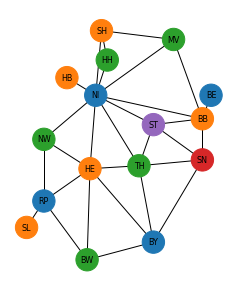

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

nachbarn = {'BW': ['BY', 'HE', 'RP'], 'BY': ['HE', 'TH', 'SN'], 'BE': ['BB'], 'BB': ['MV', 'SN', 'ST', 'NI'], 'HB': ['NI'], 'HH': ['SH', 'NI'],
            'HE': ['TH', 'NI', 'NW', 'RP'], 'MV': ['SH', 'NI'], 'NI': ['SH', 'ST', 'TH', 'NW'], 'NW': ['RP'], 'RP': ['SL'], 'SN': ['TH', 'ST'], 'ST': ['TH']}
D = nx.Graph(nachbarn)
pos = {'SH': (3, 9), 'HH': (3.2, 8), 'MV': (5.5, 8.7), 'HB': (1.8, 7.4), 'NI': (2.8, 6.8), 'BE': (6.8, 6.8), 'BB': (6.5, 6), 'ST': (4.8, 5.8),
       'NW': (1, 5.3), 'HE': (2.6, 4.3), 'TH': (4.3, 4.4), 'SN': (6.5, 4.6), 'RP': (1, 3.2), 'SL': (0.4, 2.3), 'BW': (2.5, 1.2), 'BY': (4.8, 1.8)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import networkx as nx

nachbarn = {'BW': ['BY', 'HE', 'RP'], 'BY': ['HE', 'TH', 'SN'], 'BE': ['BB'], 'BB': ['MV', 'SN', 'ST', 'NI'], 'HB': ['NI'], 'HH': ['SH', 'NI'],
            'HE': ['TH', 'NI', 'NW', 'RP'], 'MV': ['SH', 'NI'], 'NI': ['SH', 'ST', 'TH', 'NW'], 'NW': ['RP'], 'RP': ['SL'], 'SN': ['TH', 'ST'], 'ST': ['TH']}
D = nx.Graph(nachbarn)
pos = {'SH': (3, 9), 'HH': (3.2, 8), 'MV': (5.5, 8.7), 'HB': (1.8, 7.4), 'NI': (2.8, 6.8), 'BE': (6.8, 6.8), 'BB': (6.5, 6), 'ST': (4.8, 5.8),
       'NW': (1, 5.3), 'HE': (2.6, 4.3), 'TH': (4.3, 4.4), 'SN': (6.5, 4.6), 'RP': (1, 3.2), 'SL': (0.4, 2.3), 'BW': (2.5, 1.2), 'BY': (4.8, 1.8)}
farben = nx.greedy_color(D)
liste = []
for land in D.nodes:
    liste.append(f'C{farben[land]}')
fig, ax = plt.subplots(figsize=(4, 5))
nx.draw(D, pos, ax=ax, with_labels=True, node_color=liste, node_size=500, font_size=8)
plt.show()
```

</details>

#### Aufgabe 2.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import networkx as nx

G = nx.cycle_graph(4)
f = nx.greedy_color(G)
print(max(f.values()) + 1)
G.add_edge(0, 2)
print(max(nx.greedy_color(G).values()) + 1)

## 3. Dominating Sets

#### Jeder Knoten ist versorgt

Eine Menge D von Knoten ist **dominierend** (ein *Dominating Set*), wenn jeder Knoten **in D liegt oder einen Nachbarn in D hat**. Beispiel: An welchen Orten braucht man Feuerwachen,
damit jeder Ort eine Wache hat oder an einen Ort mit Wache grenzt? Gesucht ist ein möglichst **kleines** Dominating Set; auch das ist ein schweres Problem.

- `nx.is_dominating_set(G, menge)` prüft, ob eine Menge dominierend ist.
- `approximation.min_weighted_dominating_set(G)` aus `networkx.algorithms.approximation` liefert eine **Näherung** mit einem Greedy-Verfahren: Es wählt immer den Knoten,
  der am meisten noch nicht versorgte Knoten versorgt. Das Ergebnis ist eine Menge (zum Ausgeben sortieren).
- Bei kleinen Graphen findet man das kleinste durch **Ausprobieren** aller Teilmengen mit `combinations`.

In [ ]:
from itertools import combinations
import networkx as nx
from networkx.algorithms import approximation

G = nx.Graph([(1, 2), (1, 3), (1, 4), (4, 5), (5, 6), (5, 7)])
print(nx.is_dominating_set(G, {1, 5}), nx.is_dominating_set(G, {2, 6}))
print(sorted(approximation.min_weighted_dominating_set(G)))
for k in range(1, G.number_of_nodes() + 1):
    loesungen = []
    for menge in combinations(G.nodes, k):
        if nx.is_dominating_set(G, menge):
            loesungen.append(menge)
    if loesungen:
        print(k, loesungen)
        break

#### Aufgabe 3.1

In welchen Orten von `O` braucht man Feuerwachen? Gib die Greedy-Näherung (sortiert) und ihre Größe aus und prüfe mit `is_dominating_set`, dass sie wirklich alle Orte versorgt.

**Erwartete Ausgabe:**
```
['B', 'E', 'F', 'H'] 4
True
```

In [ ]:
import networkx as nx
from networkx.algorithms import approximation

O = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F'), ('E', 'G'), ('F', 'G'), ('G', 'H'), ('H', 'I'), ('F', 'I')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx
from networkx.algorithms import approximation

O = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F'), ('E', 'G'), ('F', 'G'), ('G', 'H'), ('H', 'I'), ('F', 'I')])
wachen = approximation.min_weighted_dominating_set(O)
print(sorted(wachen), len(wachen))
print(nx.is_dominating_set(O, wachen))
```

</details>

#### Aufgabe 3.2

Finde durch Ausprobieren die **kleinste** Anzahl von Wachen für `O` und gib alle kleinsten Lösungen aus (als Tupel, in der Reihenfolge von `combinations`). Vergleiche mit der Größe der Greedy-Näherung.

**Erwartete Ausgabe:**
```
3 [('A', 'D', 'H'), ('A', 'E', 'I'), ('A', 'F', 'G'), ('B', 'D', 'H'), ('B', 'E', 'I'), ('B', 'F', 'G'), ('B', 'G', 'H'), ('B', 'G', 'I'), ('C', 'D', 'H'), ('C', 'E', 'I'), ('C', 'F', 'G'), ('C', 'F', 'H'), ('C', 'F', 'I')]
4
```

In [ ]:
import networkx as nx
from networkx.algorithms import approximation

O = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F'), ('E', 'G'), ('F', 'G'), ('G', 'H'), ('H', 'I'), ('F', 'I')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx
from networkx.algorithms import approximation

O = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F'), ('E', 'G'), ('F', 'G'), ('G', 'H'), ('H', 'I'), ('F', 'I')])
from itertools import combinations

for k in range(1, O.number_of_nodes() + 1):
    loesungen = []
    for menge in combinations(O.nodes, k):
        if nx.is_dominating_set(O, menge):
            loesungen.append(menge)
    if loesungen:
        print(k, loesungen)
        break
print(len(approximation.min_weighted_dominating_set(O)))
```

</details>

#### Aufgabe 3.3

Gib für die Lösung `{'B', 'G'}` aus, welche Orte nicht versorgt sind (weder selbst Wache noch Nachbar einer Wache), sortiert.

**Erwartete Ausgabe:**
```
['I']
```

In [ ]:
import networkx as nx
from networkx.algorithms import approximation

O = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F'), ('E', 'G'), ('F', 'G'), ('G', 'H'), ('H', 'I'), ('F', 'I')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx
from networkx.algorithms import approximation

O = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E'), ('D', 'F'), ('E', 'G'), ('F', 'G'), ('G', 'H'), ('H', 'I'), ('F', 'I')])
wachen = {'B', 'G'}
versorgt = set(wachen)
for w in wachen:
    versorgt |= set(O.neighbors(w))
print(sorted(set(O.nodes) - versorgt))
```

</details>

#### Aufgabe 3.4

WLAN-Router auf einem Gitter: Die Räume eines Stockwerks bilden `nx.grid_2d_graph(3, 4)`; ein Router versorgt seinen Raum und die direkt angrenzenden. Gib die Größe der Greedy-Näherung aus
und die kleinste Anzahl durch Ausprobieren (k ab 1).

**Erwartete Ausgabe:**
```
6
4
```

In [ ]:
from itertools import combinations
import networkx as nx
from networkx.algorithms import approximation

G = nx.grid_2d_graph(3, 4)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from itertools import combinations
import networkx as nx
from networkx.algorithms import approximation

G = nx.grid_2d_graph(3, 4)
print(len(approximation.min_weighted_dominating_set(G)))
k = 1
while True:
    gefunden = False
    for menge in combinations(G.nodes, k):
        if nx.is_dominating_set(G, menge):
            gefunden = True
            break
    if gefunden:
        break
    k += 1
print(k)
```

</details>

#### Aufgabe 3.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import networkx as nx

S = nx.Graph([(0, 1), (0, 2), (0, 3), (0, 4)])
print(nx.is_dominating_set(S, {0}), nx.is_dominating_set(S, {1, 2, 3}))
print(nx.is_dominating_set(S, {1, 2, 3, 4}))

## 4. Rundreisen

#### Das Problem des Handlungsreisenden

Ein Vertreter will alle Städte genau einmal besuchen und zum Start zurückkehren, auf einer möglichst **kurzen Rundreise** (*Traveling Salesman Problem*, TSP).
Bei n Städten gibt es (n − 1)!/2 verschiedene Rundreisen. Schon bei 20 Städten sind das über 10¹⁶: Alle durchzuprobieren dauert viel zu lange. Ein schnelles Verfahren,
das immer die beste Rundreise findet, ist nicht bekannt.

Die **Nächster-Nachbar-Heuristik** (Greedy) fährt immer zur nächstgelegenen noch nicht besuchten Stadt:
`approximation.greedy_tsp(G, source=start)` gibt die Rundreise als Liste von Knoten zurück (Start am Ende noch einmal). `G` muss **vollständig** sein (jede Stadt mit jeder verbunden).

In [ ]:
from itertools import permutations
import networkx as nx
from networkx.algorithms import approximation

G = nx.Graph()
G.add_weighted_edges_from([('A', 'B', 2), ('A', 'C', 9), ('A', 'D', 10), ('B', 'C', 6), ('B', 'D', 4), ('C', 'D', 3)])
tour = approximation.greedy_tsp(G, source='A')
print(tour, nx.path_weight(G, tour, weight='weight'))
beste = None
for reihe in permutations(['B', 'C', 'D']):
    t = ['A'] + list(reihe) + ['A']
    laenge = nx.path_weight(G, t, weight='weight')
    if beste is None or laenge < beste[1]:
        beste = (t, laenge)
print(beste)

`math.dist(p, q)` ist der Abstand zweier Punkte, die als Tupel gegeben sind. Damit baut man einen vollständigen Graphen aus Koordinaten.

In [ ]:
import math

print(math.dist((0, 0), (3, 4)))

#### Aufgabe 4.1

Gib die Rundreise der Nächster-Nachbar-Heuristik ab A und ihre Länge (2 Stellen) aus.

**Erwartete Ausgabe:**
```
['A', 'D', 'F', 'B', 'C', 'E', 'A'] 31.27
```

In [ ]:
import math
import networkx as nx
from networkx.algorithms import approximation

orte = {'A': (0, 0), 'B': (9, 1), 'C': (9, 0), 'D': (2, 0), 'E': (4, 8), 'F': (6, 4)}
G = nx.Graph()
for u in orte:
    for v in orte:
        if u < v:
            G.add_edge(u, v, weight=round(math.dist(orte[u], orte[v]), 2))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
import networkx as nx
from networkx.algorithms import approximation

orte = {'A': (0, 0), 'B': (9, 1), 'C': (9, 0), 'D': (2, 0), 'E': (4, 8), 'F': (6, 4)}
G = nx.Graph()
for u in orte:
    for v in orte:
        if u < v:
            G.add_edge(u, v, weight=round(math.dist(orte[u], orte[v]), 2))
tour = approximation.greedy_tsp(G, source='A')
print(tour, round(nx.path_weight(G, tour, weight='weight'), 2))
```

</details>

#### Aufgabe 4.2

Finde die kürzeste Rundreise ab A durch Ausprobieren aller Reihenfolgen der anderen Städte (`permutations`) und gib sie mit Länge (2 Stellen) aus. Gib außerdem aus, um wie viel Prozent die
Greedy-Rundreise länger ist (1 Stelle).

**Erwartete Ausgabe:**
```
['A', 'D', 'C', 'B', 'F', 'E', 'A'] 27.65
13.1
```

In [ ]:
import math
import networkx as nx
from networkx.algorithms import approximation

orte = {'A': (0, 0), 'B': (9, 1), 'C': (9, 0), 'D': (2, 0), 'E': (4, 8), 'F': (6, 4)}
G = nx.Graph()
for u in orte:
    for v in orte:
        if u < v:
            G.add_edge(u, v, weight=round(math.dist(orte[u], orte[v]), 2))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
import networkx as nx
from networkx.algorithms import approximation

orte = {'A': (0, 0), 'B': (9, 1), 'C': (9, 0), 'D': (2, 0), 'E': (4, 8), 'F': (6, 4)}
G = nx.Graph()
for u in orte:
    for v in orte:
        if u < v:
            G.add_edge(u, v, weight=round(math.dist(orte[u], orte[v]), 2))
from itertools import permutations

andere = []
for o in orte:
    if o != 'A':
        andere.append(o)
beste = None
for reihe in permutations(andere):
    tour = ['A'] + list(reihe) + ['A']
    laenge = nx.path_weight(G, tour, weight='weight')
    if beste is None or laenge < beste[1]:
        beste = (tour, laenge)
print(beste[0], round(beste[1], 2))
greedy = nx.path_weight(G, approximation.greedy_tsp(G, source='A'), weight='weight')
print(round((greedy / beste[1] - 1) * 100, 1))
```

</details>

#### Aufgabe 4.3

Die Greedy-Rundreise hängt vom Start ab. Gib für jeden Startort die Länge der Greedy-Rundreise (2 Stellen) aus.

**Erwartete Ausgabe:**
```
A 31.27
B 29.78
C 28.96
D 32.13
E 27.65
F 27.65
```

In [ ]:
import math
import networkx as nx
from networkx.algorithms import approximation

orte = {'A': (0, 0), 'B': (9, 1), 'C': (9, 0), 'D': (2, 0), 'E': (4, 8), 'F': (6, 4)}
G = nx.Graph()
for u in orte:
    for v in orte:
        if u < v:
            G.add_edge(u, v, weight=round(math.dist(orte[u], orte[v]), 2))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
import networkx as nx
from networkx.algorithms import approximation

orte = {'A': (0, 0), 'B': (9, 1), 'C': (9, 0), 'D': (2, 0), 'E': (4, 8), 'F': (6, 4)}
G = nx.Graph()
for u in orte:
    for v in orte:
        if u < v:
            G.add_edge(u, v, weight=round(math.dist(orte[u], orte[v]), 2))
for start in orte:
    tour = approximation.greedy_tsp(G, source=start)
    print(start, round(nx.path_weight(G, tour, weight='weight'), 2))
```

</details>

#### Aufgabe 4.4

Wie schnell wächst die Zahl der Rundreisen? Gib für n = 4, 6, 8, 10, 15, 20 die Zahl (n − 1)!/2 aus (`math.factorial`) und die Dauer in Jahren, wenn ein Computer
eine Milliarde Rundreisen pro Sekunde prüft (2 Stellen in wissenschaftlicher Schreibweise mit `:.2e`).

**Erwartete Ausgabe:**
```
4 3 9.51e-17
6 60 1.90e-15
8 2520 7.99e-14
10 181440 5.75e-12
15 43589145600 1.38e-06
20 60822550204416000 1.93e+00
```

In [ ]:
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
for n in [4, 6, 8, 10, 15, 20]:
    anzahl = math.factorial(n - 1) // 2
    jahre = anzahl / 1e9 / (365 * 24 * 3600)
    print(n, anzahl, f'{jahre:.2e}')
```

</details>

#### Aufgabe 4.5

Zeichne die Orte mit ihren Koordinaten (`pos = orte`), alle Verbindungen sehr hell (`edge_color='whitesmoke'`) und die Greedy-Rundreise ab A rot (Kanten aufeinanderfolgender Orte der Tour mit
`nx.draw_networkx_edges(..., edgelist=..., edge_color='red', width=2)`). Knoten `'lightblue'` mit Beschriftung. Bildgröße 4 × 3.

**Erwartete Ausgabe:**

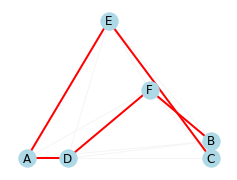

In [ ]:
import matplotlib.pyplot as plt
import math
import networkx as nx
from networkx.algorithms import approximation

orte = {'A': (0, 0), 'B': (9, 1), 'C': (9, 0), 'D': (2, 0), 'E': (4, 8), 'F': (6, 4)}
G = nx.Graph()
for u in orte:
    for v in orte:
        if u < v:
            G.add_edge(u, v, weight=round(math.dist(orte[u], orte[v]), 2))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import math
import networkx as nx
from networkx.algorithms import approximation

orte = {'A': (0, 0), 'B': (9, 1), 'C': (9, 0), 'D': (2, 0), 'E': (4, 8), 'F': (6, 4)}
G = nx.Graph()
for u in orte:
    for v in orte:
        if u < v:
            G.add_edge(u, v, weight=round(math.dist(orte[u], orte[v]), 2))
tour = approximation.greedy_tsp(G, source='A')
kanten = []
for i in range(len(tour) - 1):
    kanten.append((tour[i], tour[i + 1]))
fig, ax = plt.subplots(figsize=(4, 3))
nx.draw(G, orte, ax=ax, with_labels=True, node_color='lightblue', edge_color='whitesmoke')
nx.draw_networkx_edges(G, orte, ax=ax, edgelist=kanten, edge_color='red', width=2)
plt.show()
```

</details>

`edgelist=[...]` bei `nx.draw_networkx_edges` zeichnet nur die angegebenen Kanten.

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.cycle_graph(4)
pos = {0: (0, 0), 1: (1, 0), 2: (1, 1), 3: (0, 1)}
fig, ax = plt.subplots(figsize=(2, 2))
nx.draw(G, pos, ax=ax, edge_color='lightgray')
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=[(0, 1), (1, 2)], edge_color='red', width=2)
plt.show()

## 5. Soziale Netze

#### Wer ist wichtig?

In sozialen Netzen fragt man, welche Personen besonders **zentral** sind:

- **Grad-Zentralität** `nx.degree_centrality(G)`: Anteil aller anderen Personen, mit denen man direkt verbunden ist (Grad / (n − 1)).
- **Betweenness-Zentralität** `nx.betweenness_centrality(G)`: Wie oft liegt eine Person auf kürzesten Wegen zwischen anderen? Wer hoch liegt, ist eine **Brücke** zwischen Gruppen.

Beides sind Dictionaries Person → Wert zwischen 0 und 1.

In [ ]:
import networkx as nx

G = nx.Graph([('a', 'b'), ('a', 'c'), ('b', 'c'), ('c', 'd'), ('d', 'e'), ('e', 'f'), ('d', 'f')])
print(nx.degree_centrality(G)['c'])
b = nx.betweenness_centrality(G)
for v in G.nodes:
    print(v, round(b[v], 3))

#### Aufgabe 5.1

Gib für jede Person der Klasse die Grad-Zentralität (3 Stellen) aus, die zentralste zuerst.

**Erwartete Ausgabe:**
```
Dana 0.5
Bea 0.375
Cem 0.375
Fiona 0.375
Gus 0.375
Ali 0.25
Emil 0.25
Hanna 0.25
Ida 0.25
```

In [ ]:
import networkx as nx

K = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Cem', 'Dana'), ('Dana', 'Emil'), ('Dana', 'Fiona'), ('Emil', 'Fiona'),
              ('Fiona', 'Gus'), ('Gus', 'Hanna'), ('Gus', 'Ida'), ('Hanna', 'Ida'), ('Bea', 'Dana')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

K = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Cem', 'Dana'), ('Dana', 'Emil'), ('Dana', 'Fiona'), ('Emil', 'Fiona'),
              ('Fiona', 'Gus'), ('Gus', 'Hanna'), ('Gus', 'Ida'), ('Hanna', 'Ida'), ('Bea', 'Dana')])
g = nx.degree_centrality(K)
for p in sorted(g, key=lambda p: g[p], reverse=True):
    print(p, round(g[p], 3))
```

</details>

#### Aufgabe 5.2

Gib die Person mit der höchsten Betweenness-Zentralität und den Wert (3 Stellen) aus. Gib außerdem alle Personen mit Betweenness 0 sortiert aus.

**Erwartete Ausgabe:**
```
Dana 0.536
['Ali', 'Emil', 'Hanna', 'Ida']
```

In [ ]:
import networkx as nx

K = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Cem', 'Dana'), ('Dana', 'Emil'), ('Dana', 'Fiona'), ('Emil', 'Fiona'),
              ('Fiona', 'Gus'), ('Gus', 'Hanna'), ('Gus', 'Ida'), ('Hanna', 'Ida'), ('Bea', 'Dana')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

K = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Cem', 'Dana'), ('Dana', 'Emil'), ('Dana', 'Fiona'), ('Emil', 'Fiona'),
              ('Fiona', 'Gus'), ('Gus', 'Hanna'), ('Gus', 'Ida'), ('Hanna', 'Ida'), ('Bea', 'Dana')])
b = nx.betweenness_centrality(K)
p = max(b, key=lambda v: b[v])
print(p, round(b[p], 3))
null = []
for v, wert in b.items():
    if wert == 0:
        null.append(v)
print(sorted(null))
```

</details>

#### Aufgabe 5.3

Was passiert, wenn Fiona die Klasse verlässt? Entferne sie und gib die Gruppen (Zusammenhangskomponenten, jeweils sortiert, nach dem ersten Namen sortiert) aus.

**Erwartete Ausgabe:**
```
[['Ali', 'Bea', 'Cem', 'Dana', 'Emil'], ['Gus', 'Hanna', 'Ida']]
```

In [ ]:
import networkx as nx

K = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Cem', 'Dana'), ('Dana', 'Emil'), ('Dana', 'Fiona'), ('Emil', 'Fiona'),
              ('Fiona', 'Gus'), ('Gus', 'Hanna'), ('Gus', 'Ida'), ('Hanna', 'Ida'), ('Bea', 'Dana')])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

K = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Cem', 'Dana'), ('Dana', 'Emil'), ('Dana', 'Fiona'), ('Emil', 'Fiona'),
              ('Fiona', 'Gus'), ('Gus', 'Hanna'), ('Gus', 'Ida'), ('Hanna', 'Ida'), ('Bea', 'Dana')])
K.remove_node('Fiona')
gruppen = []
for k in nx.connected_components(K):
    gruppen.append(sorted(k))
print(sorted(gruppen))
```

</details>

#### Aufgabe 5.4

„Freunde von Freunden“: Schlage jeder Person aus der Liste `personen` neue Freunde vor: alle Personen, mit denen sie mindestens einen gemeinsamen Freund hat, die aber noch nicht
ihre Freunde sind. Gib die Vorschläge mit der Anzahl gemeinsamer Freunde aus (sortiert nach Namen), in der Form `Ali: {'Dana': 2}`.

**Erwartete Ausgabe:**
```
Ali: {'Dana': 2}
Emil: {'Bea': 1, 'Cem': 1, 'Gus': 1}
```

In [ ]:
import networkx as nx

K = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Cem', 'Dana'), ('Dana', 'Emil'), ('Dana', 'Fiona'), ('Emil', 'Fiona'),
              ('Fiona', 'Gus'), ('Gus', 'Hanna'), ('Gus', 'Ida'), ('Hanna', 'Ida'), ('Bea', 'Dana')])
personen = ['Ali', 'Emil']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

K = nx.Graph([('Ali', 'Bea'), ('Ali', 'Cem'), ('Bea', 'Cem'), ('Cem', 'Dana'), ('Dana', 'Emil'), ('Dana', 'Fiona'), ('Emil', 'Fiona'),
              ('Fiona', 'Gus'), ('Gus', 'Hanna'), ('Gus', 'Ida'), ('Hanna', 'Ida'), ('Bea', 'Dana')])
personen = ['Ali', 'Emil']
for p in personen:
    vorschlaege = {}
    for f in K.neighbors(p):
        for ff in K.neighbors(f):
            if ff != p and not K.has_edge(p, ff):
                vorschlaege[ff] = vorschlaege.get(ff, 0) + 1
    sortiert = {}
    for name in sorted(vorschlaege):
        sortiert[name] = vorschlaege[name]
    print(f'{p}: {sortiert}')
```

</details>

#### Aufgabe 5.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import networkx as nx

S = nx.Graph([(0, 1), (0, 2), (0, 3), (0, 4)])
print(nx.degree_centrality(S)[0], nx.degree_centrality(S)[1])
print(nx.betweenness_centrality(S)[0], nx.betweenness_centrality(S)[1])

## 6. Gemischte Übungen

#### Aufgabe 6.1

Ein Postbote muss jede Straße (`P`, Gewicht: Länge in m) mindestens einmal ablaufen und zurück zur Post. Prüfe, ob ein Euler-Kreis existiert. Wenn nicht, gib die Knoten mit ungeradem Grad
(sortiert) und die Länge des kürzesten Weges zwischen ihnen aus (dieser Weg muss doppelt gelaufen werden). Gib zum Schluss die Gesamtlänge der Tour aus.

**Erwartete Ausgabe:**
```
False
['a', 'd']
500
2650.0
```

In [ ]:
import networkx as nx

P = nx.Graph()
P.add_weighted_edges_from([('Post', 'a', 300), ('a', 'b', 200), ('b', 'Post', 250), ('b', 'c', 400), ('c', 'd', 150), ('d', 'b', 350), ('a', 'd', 500)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

P = nx.Graph()
P.add_weighted_edges_from([('Post', 'a', 300), ('a', 'b', 200), ('b', 'Post', 250), ('b', 'c', 400), ('c', 'd', 150), ('d', 'b', 350), ('a', 'd', 500)])
print(nx.is_eulerian(P))
ungerade = []
for v in P.nodes:
    if P.degree(v) % 2 == 1:
        ungerade.append(v)
ungerade.sort()
print(ungerade)
extra = nx.dijkstra_path_length(P, ungerade[0], ungerade[1])
print(extra)
print(P.size(weight='weight') + extra)
```

</details>

#### Aufgabe 6.2

Ein Sudoku-ähnliches Rätsel als Färbung: Die Felder eines 4 × 4-Gitters (`grid_2d_graph`) sollen so gefärbt werden, dass benachbarte Felder **und** Felder in derselben Zeile oder Spalte verschiedene Farben
haben. Baue den Graphen (jedes Feld mit allen anderen Feldern derselben Zeile und Spalte verbinden) und gib die Zahl der Farben von `greedy_color` aus.

**Erwartete Ausgabe:**
```
16 48
4
```

In [ ]:
import networkx as nx
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx
G = nx.Graph()
for z1 in range(4):
    for s1 in range(4):
        for z2 in range(4):
            for s2 in range(4):
                if (z1, s1) != (z2, s2) and (z1 == z2 or s1 == s2):
                    G.add_edge((z1, s1), (z2, s2))
print(G.number_of_nodes(), G.number_of_edges())
print(max(nx.greedy_color(G).values()) + 1)
```

</details>

#### Aufgabe 6.3

Ein Kino-Netzwerk (`N`): Für jede Stadt soll ein Dominating Set aus Kinos bestimmt werden, aber jedes Kino kostet unterschiedlich viel (Knotenattribut `kosten`).
`approximation.min_weighted_dominating_set(N, weight='kosten')` berücksichtigt die Kosten. Gib die gewählten Orte (sortiert) und die Gesamtkosten für die Näherung ohne und mit Kosten aus.

**Erwartete Ausgabe:**
```
['B', 'C', 'E'] 24
['A', 'D', 'F'] 10
```

In [ ]:
import networkx as nx
from networkx.algorithms import approximation

N = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('B', 'E'), ('E', 'F')])
for ort, k in {'A': 5, 'B': 9, 'C': 8, 'D': 2, 'E': 7, 'F': 3}.items():
    N.nodes[ort]['kosten'] = k
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx
from networkx.algorithms import approximation

N = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('B', 'E'), ('E', 'F')])
for ort, k in {'A': 5, 'B': 9, 'C': 8, 'D': 2, 'E': 7, 'F': 3}.items():
    N.nodes[ort]['kosten'] = k
for gewicht in [None, 'kosten']:
    auswahl = approximation.min_weighted_dominating_set(N, weight=gewicht)
    kosten = 0
    for ort in auswahl:
        kosten += N.nodes[ort]['kosten']
    print(sorted(auswahl), kosten)
```

</details>

#### Aufgabe 6.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import networkx as nx

G = nx.complete_graph(4)
print(nx.is_eulerian(G), nx.has_eulerian_path(G))
print(max(nx.greedy_color(G).values()) + 1)